In [7]:
# Retry with a simpler (and more robust) symmetry test:
# Enforce R^T A R = A at three distinct angles and solve for (a,b,c).
# Also include the infinitesimal-rotation commutator proof.

import sympy as sp

a, b, c = sp.symbols('a b c', real=True)
theta = sp.symbols('theta', real=True)

R = sp.Matrix([[sp.cos(theta), -sp.sin(theta)],
               [sp.sin(theta),  sp.cos(theta)]])
A = sp.Matrix([[a, b],
               [b, c]])

RtAR = sp.simplify(R.T * A * R)
Delta = sp.simplify(RtAR - A)

# Build equations by sampling Δ(θ) at a small set of angles (enough to kill sin/cos components)
angles = [0, sp.pi/4, sp.pi/2]
eqs = []
for ang in angles:
    Dv = sp.simplify(Delta.subs(theta, ang))
    # require every entry to be zero at this angle
    for i in range(2):
        for j in range(2):
            eqs.append(sp.Eq(sp.simplify(Dv[i,j]), 0))

sol = sp.solve(eqs, (a,b,c), dict=True)

print("=== Solving invariance from R^T A R = A at θ ∈ {0, π/4, π/2} ===")
print("Equations:")
for e in eqs:
    print(" ", e)
print("\nSolutions for (a,b,c):", sol)

# Derive explicit relations rather than a concrete triple.
# Typically SymPy gives a relation set; if it returns an empty list (meaning underdetermined),
# we can compute relations from a single symbolic off-diagonal entry.
if not sol:
    off = sp.simplify(Delta[0,1])
    off2 = sp.simplify(sp.expand_trig(off.rewrite(sp.sin)))
    print("\nOff-diagonal Δ12(θ):", off2)
    # Express off2 = A*sin(2θ) + B*cos(2θ). Extract A and B by evaluating at θ=0 and θ=π/4.
    Acoef = sp.simplify(sp.diff(off2, sp.sin(2*theta)).subs({theta: sp.pi/4}))
    Bcoef = sp.simplify(sp.diff(off2, sp.cos(2*theta)).subs({theta: 0}))
    print("Heuristic coefficients A (sin 2θ) and B (cos 2θ):", Acoef, Bcoef)

# Infinitesimal method
J = sp.Matrix([[0, -1],
               [1,  0]])
comm = sp.simplify(A*J - J*A)
eqs_comm = [sp.Eq(comm[0,0],0), sp.Eq(comm[0,1],0), sp.Eq(comm[1,0],0), sp.Eq(comm[1,1],0)]
sol_comm = sp.solve(eqs_comm, (a,b,c), dict=True)

print("\n=== Infinitesimal method ([A,J]=0) ===")
print("Commutator [A,J]:")
sp.pprint(comm)
print("\nSolutions for (a,b,c) from [A,J]=0:", sol_comm)

# As a final sanity check, verify that A = α I satisfies invariance symbolically.
alpha = sp.symbols('alpha', real=True)
A_iso = alpha * sp.eye(2)
check = sp.simplify(R.T * A_iso * R - A_iso)
print("\nSanity check: with A = α I, R^T A R - A equals")
sp.pprint(check)

=== Solving invariance from R^T A R = A at θ ∈ {0, π/4, π/2} ===
Equations:
  True
  True
  True
  True
  Eq(-a/2 + b + c/2, 0)
  Eq(-a/2 - b + c/2, 0)
  Eq(-a/2 - b + c/2, 0)
  Eq(a/2 - b - c/2, 0)
  Eq(-a + c, 0)
  Eq(-2*b, 0)
  Eq(-2*b, 0)
  Eq(a - c, 0)

Solutions for (a,b,c): [{a: c, b: 0}]

=== Infinitesimal method ([A,J]=0) ===
Commutator [A,J]:
⎡ 2⋅b    -a + c⎤
⎢              ⎥
⎣-a + c   -2⋅b ⎦

Solutions for (a,b,c) from [A,J]=0: [{a: c, b: 0}]

Sanity check: with A = α I, R^T A R - A equals
⎡0  0⎤
⎢    ⎥
⎣0  0⎦


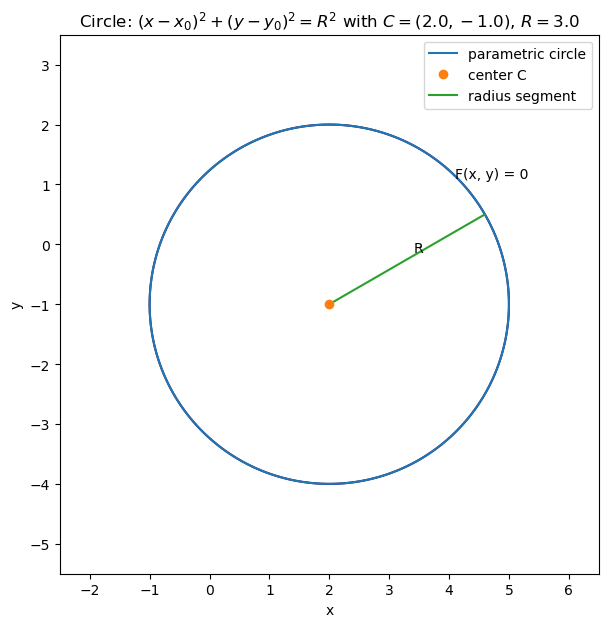

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D  # only needed if you want a legend entry for F=0

# ---- parameters ----
x0, y0 = 2.0, -1.0
R = 3.0

# ---- domain ----
pad = 1.5 * R
x_min, x_max = x0 - pad, x0 + pad
y_min, y_max = y0 - pad, y0 + pad

# ---- parametric circle ----
theta = np.linspace(0.0, 2.0*np.pi, 800, endpoint=True)
x_param = x0 + R*np.cos(theta)
y_param = y0 + R*np.sin(theta)

# ---- level set grid ----
nx = ny = 500
xs = np.linspace(x_min, x_max, nx)
ys = np.linspace(y_min, y_max, ny)
X, Y = np.meshgrid(xs, ys, indexing="xy")
F = (X - x0)**2 + (Y - y0)**2 - R**2

# ---- a convenient radius to label ----
phi = np.pi/6.0
xR = x0 + R*np.cos(phi)
yR = y0 + R*np.sin(phi)

fig, ax = plt.subplots(figsize=(7, 7))

# Draw level set first (more robust call with 1-D grid vectors)
ax.contour(xs, ys, F, levels=[0.0], zorder=1)

# Draw the parametric circle last so its color matches the legend entry you see
h_param, = ax.plot(x_param, y_param, label="parametric circle", zorder=3)

# Center & radius segment
ax.plot([x0], [y0], marker="o", linestyle="none", label="center C", zorder=4)
ax.plot([x0, xR], [y0, yR], linestyle="-", label="radius segment", zorder=3)
xm, ym = (x0 + xR)/2.0, (y0 + yR)/2.0
ax.annotate("R", xy=(xm, ym), xytext=(5, 5), textcoords="offset points")

# Option A (simplest): label the level set with an in-figure text instead of a legend handle
ax.text(x0 + 0.7*R, y0 + 0.7*R, "F(x, y) = 0")

# Option B (if you want it in the legend too): add a proxy handle
# proxy = Line2D([], [], linestyle='-', label="F(x, y) = 0")
# ax.legend(handles=[h_param, proxy, *ax.get_legend_handles_labels()[0][1:]], loc="upper right")

ax.set_aspect("equal", adjustable="box")
ax.set_xlim(x_min, x_max); ax.set_ylim(y_min, y_max)
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title(rf"Circle: $(x-x_0)^2+(y-y_0)^2=R^2$ with $C=({x0:.1f},{y0:.1f})$, $R={R:.1f}$")
ax.legend(loc="upper right")
plt.show()

# 2.2

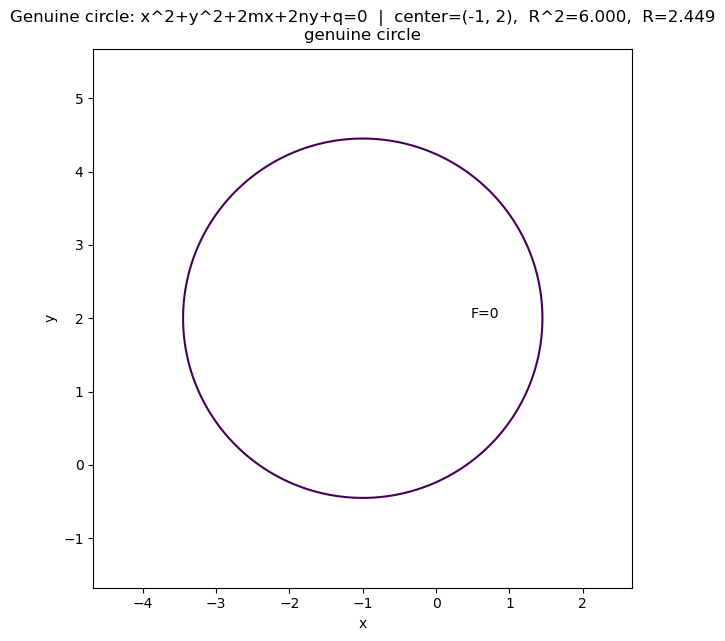

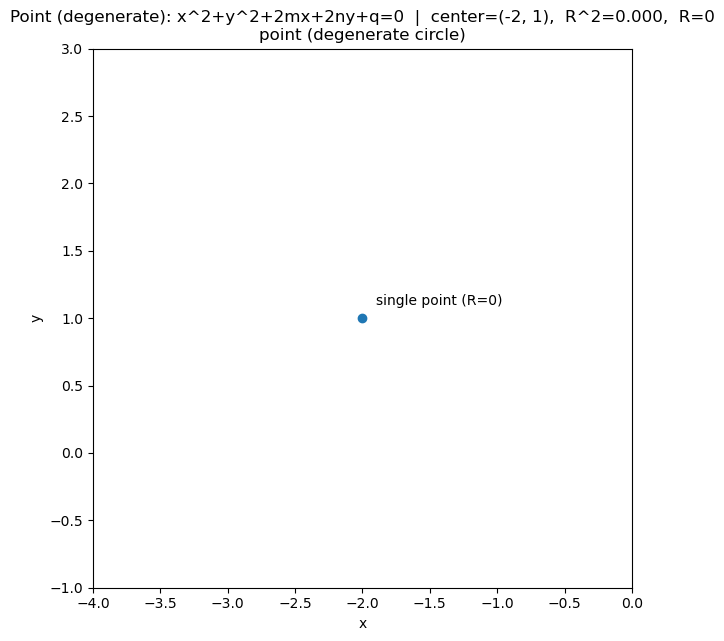

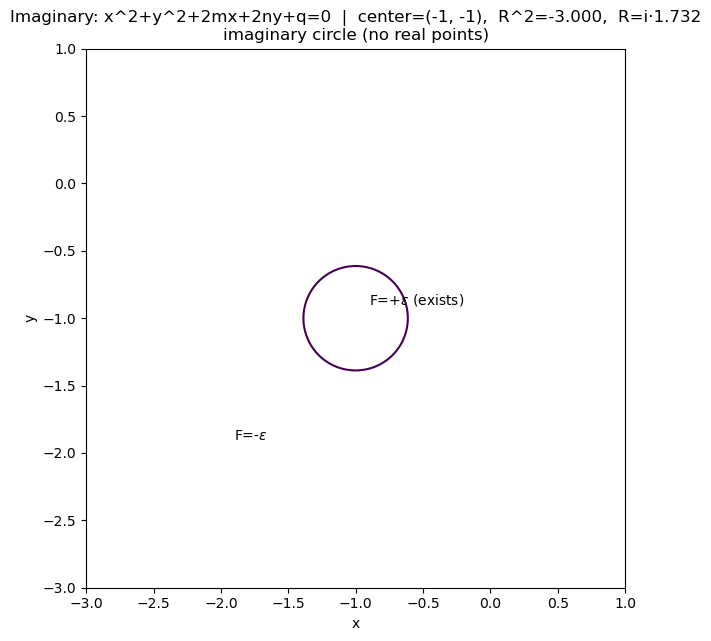

Summary (m, n, q -> x0, y0, R^2, kind):
(+1.000, -2.000, -1.000) -> x0=-1.000, y0=+2.000, R^2=+6.000  [genuine circle]
(+2.000, -1.000, +5.000) -> x0=-2.000, y0=+1.000, R^2=+0.000  [point (degenerate circle)]
(+1.000, +1.000, +5.000) -> x0=-1.000, y0=-1.000, R^2=-3.000  [imaginary circle (no real points)]


In [5]:
# Exercise 2: Complete the square and extract (x0, y0), R.
# Then generate three instances: circle (R^2>0), point (R^2=0), imaginary (R^2<0),
# and plot the level set(s) as requested.
#
# Plotting rules:
# - matplotlib only
# - one chart per figure
# - no explicit colors
#
# We optionally use SymPy to symbolically verify the completion-of-the-square identity.

import numpy as np
import matplotlib.pyplot as plt



def circle_params(m, n, q):
    """Return center (x0,y0), R^2, and a classification string."""
    x0, y0 = -m, -n
    R2 = m*m + n*n - q
    if R2 > 0:
        kind = "genuine circle"
    elif np.isclose(R2, 0.0):
        kind = "point (degenerate circle)"
    else:
        kind = "imaginary circle (no real points)"
    return (x0, y0), R2, kind

def F_grid(xs, ys, x0, y0, R2):
    """Compute F(x,y) = (x - x0)^2 + (y - y0)^2 - R^2 on a mesh grid."""
    X, Y = np.meshgrid(xs, ys, indexing="xy")
    F = (X - x0)**2 + (Y - y0)**2 - R2
    return X, Y, F

def plot_level_set(m, n, q, title_suffix="", epsilon=None):
    """Plot the requested level set(s) for the given coefficients."""
    (x0, y0), R2, kind = circle_params(m, n, q)

    # Domain sizing
    if R2 > 0:
        R = float(np.sqrt(R2))
        pad = 1.5 * R
    else:
        # For point/imaginary, choose a modest fixed pad around the would-be center.
        pad = 2.0

    x_min, x_max = x0 - pad, x0 + pad
    y_min, y_max = y0 - pad, y0 + pad

    xs = np.linspace(x_min, x_max, 600)
    ys = np.linspace(y_min, y_max, 600)

    X, Y, F = F_grid(xs, ys, x0, y0, R2)

    fig, ax = plt.subplots(figsize=(7, 7))

    if R2 > 0:
        # Genuine circle: plot F=0 as a contour
        cs = ax.contour(xs, ys, F, levels=[0.0])
        # Optional label near the circle
        ax.text(x0 + 0.6*np.sqrt(R2), y0, "F=0")
    elif np.isclose(R2, 0.0):
        # Degenerate circle: single point at (x0, y0)
        ax.plot([x0], [y0], marker='o', linestyle='none')
        ax.text(x0 + 0.1, y0 + 0.1, "single point (R=0)")
    else:
        # Imaginary circle: no F=0. Plot "best-effort" F=±epsilon.
        if epsilon is None:
            epsilon = 1.05 * abs(R2)  # choose slightly above the threshold so +epsilon exists

        # F = +epsilon
        # Draw contour if it exists in the domain
        try:
            cs1 = ax.contour(xs, ys, F, levels=[epsilon])
            ax.text(x0 + 0.1, y0 + 0.1, r"F=+$\varepsilon$ (exists)")
        except Exception:
            pass

        # F = -epsilon (this will not exist for any positive epsilon if R2<0)
        # But try and catch "no contour levels found" gracefully.
        try:
            cs2 = ax.contour(xs, ys, F, levels=[-epsilon])
            ax.text(x0 - 0.9, y0 - 0.9, r"F=-$\varepsilon$")
        except Exception:
            ax.text(x0 - 1.2, y0 - 1.0, r"F=-$\varepsilon$ (no real level)")

    ax.set_aspect('equal', adjustable='box')
    ax.set_xlim(x_min, x_max); ax.set_ylim(y_min, y_max)
    ax.set_xlabel("x"); ax.set_ylabel("y")

    x0s = f"{x0:.3f}".rstrip('0').rstrip('.')
    y0s = f"{y0:.3f}".rstrip('0').rstrip('.')
    if R2 >= 0:
        Rs = f"{np.sqrt(max(R2,0.0)):.3f}".rstrip('0').rstrip('.')
    else:
        Rs = f"i·{np.sqrt(abs(R2)):.3f}".rstrip('0').rstrip('.')

    ax.set_title(
        f"{title_suffix}  |  center=({x0s}, {y0s}),  R^2={R2:.3f},  R={Rs}\n"
        f"{kind}"
    )
    plt.show()
    return (x0, y0), R2, kind

# -------------------- Three instances --------------------
instances = [
    # genuine circle: m^2 + n^2 - q > 0
    dict(m=1.0, n=-2.0, q=-1.0, label="Genuine circle: x^2+y^2+2mx+2ny+q=0"),
    # point (degenerate): m^2 + n^2 - q = 0
    dict(m=2.0, n=-1.0, q=5.0, label="Point (degenerate): x^2+y^2+2mx+2ny+q=0"),
    # imaginary: m^2 + n^2 - q < 0
    dict(m=1.0, n=1.0, q=5.0, label="Imaginary: x^2+y^2+2mx+2ny+q=0"),
]

results = []
for case in instances:
    (x0, y0), R2, kind = plot_level_set(case["m"], case["n"], case["q"], title_suffix=case["label"])
    results.append((case["m"], case["n"], case["q"], x0, y0, R2, kind))

# Display a small text summary under the last figure
print("Summary (m, n, q -> x0, y0, R^2, kind):")
for m, n, q, x0, y0, R2, kind in results:
    print(f"({m:+.3f}, {n:+.3f}, {q:+.3f}) -> x0={x0:+.3f}, y0={y0:+.3f}, R^2={R2:+.3f}  [{kind}]")

# 2.3

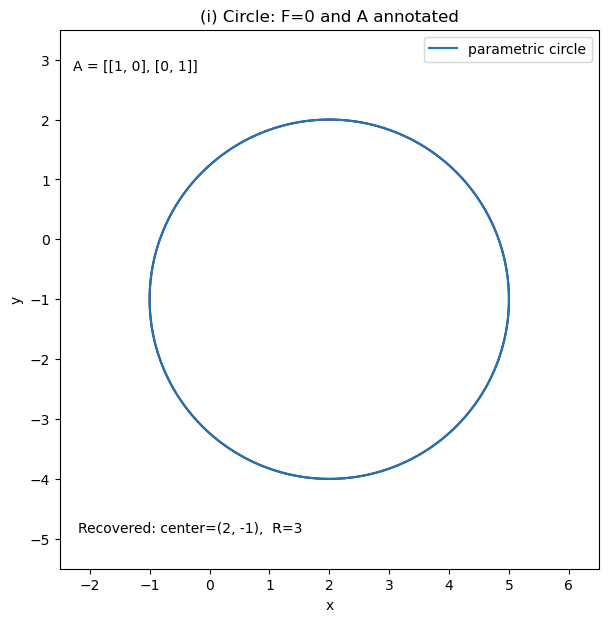

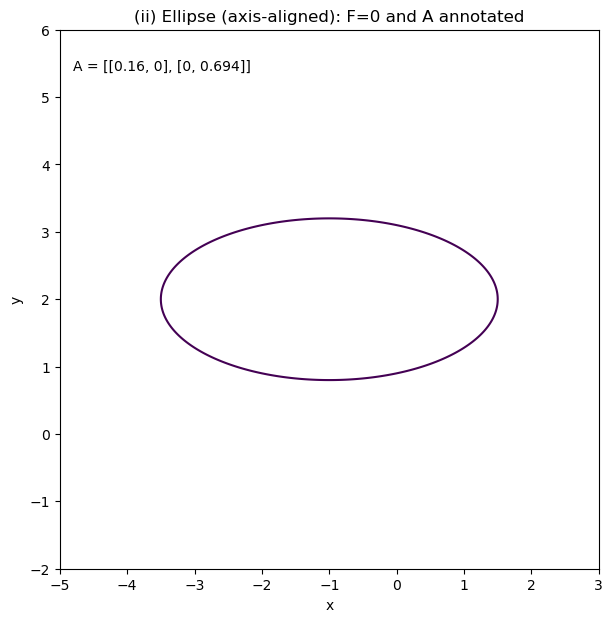

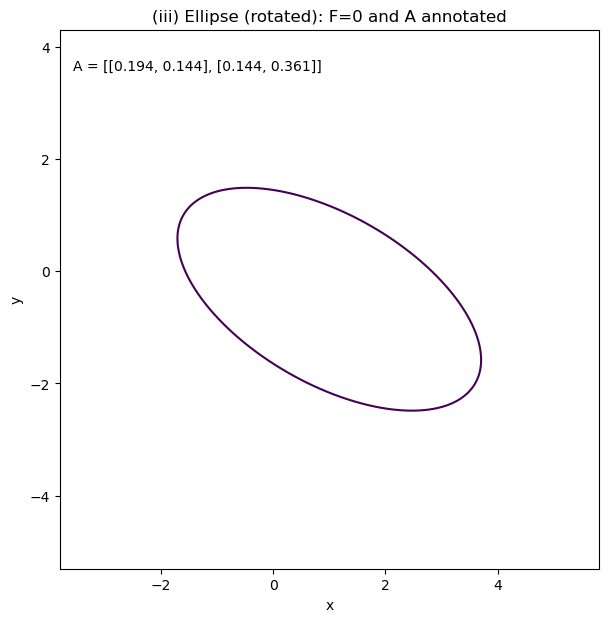

In [6]:
# Exercise 3: Recognize a circle from a general conic and visualize three cases.
# - Start with ax^2 + 2bxy + cy^2 + 2dx + 2ey + f = 0.
# - Test isotropy (circle) condition: b = 0 and a = c != 0.
# - Create three examples: (i) circle, (ii) ellipse (a != c), (iii) rotated ellipse (b != 0).
# - For each: plot level set F=0 and annotate A.
# - For the circle case: recover (x0, y0), R by completing the square and overlay the parametric circle.
#
# Plotting rules:
#   matplotlib only, one chart per figure, no explicit colors.

import numpy as np
import matplotlib.pyplot as plt

def conic_F(a, b, c, d, e, f, X, Y):
    """Evaluate F(X,Y) = a x^2 + 2 b x y + c y^2 + 2 d x + 2 e y + f on a grid."""
    return a*X*X + 2*b*X*Y + c*Y*Y + 2*d*X + 2*e*Y + f

def isotropy_test(a, b, c, tol=1e-12):
    """Return True if b=0 and a=c != 0 (within tol)."""
    return (abs(b) <= tol) and (abs(a-c) <= tol) and (abs(a) > tol)

def circle_from_conic(a, b, c, d, e, f):
    """Assuming b=0 and a=c!=0, recover (x0, y0, R)."""
    # Divide by a to reduce to x^2+y^2 + (2d/a)x + (2e/a)y + (f/a) = 0
    alpha = a
    x0 = -d / alpha
    y0 = -e / alpha
    R2 = (d*d + e*e - alpha*f) / (alpha*alpha)
    return x0, y0, R2

def plot_conic(a, b, c, d, e, f, center_hint, span_hint, title, annotate_A=True):
    """Contour F=0 on a square box centered at 'center_hint' with half-span 'span_hint'."""
    cx, cy = center_hint
    half = span_hint
    xs = np.linspace(cx-half, cx+half, 600)
    ys = np.linspace(cy-half, cy+half, 600)
    X, Y = np.meshgrid(xs, ys, indexing='xy')
    F = conic_F(a, b, c, d, e, f, X, Y)

    fig, ax = plt.subplots(figsize=(7,7))
    cs = ax.contour(xs, ys, F, levels=[0.0], zorder=1)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlim(cx-half, cx+half); ax.set_ylim(cy-half, cy+half)
    ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.set_title(title)

    if annotate_A:
        A_text = f"A = [[{a:.3g}, {b:.3g}], [{b:.3g}, {c:.3g}]]"
        # Place near upper-left inside the axes
        ax.text(cx - 0.95*half, cy + 0.85*half, A_text)

    return fig, ax

# -------------------- (i) Circle example (isotropy holds) --------------------
# Choose a clean circle: center (2, -1), R = 3, and scale alpha = 1 so a=c=1, b=0.
x0_c, y0_c, R_c = 2.0, -1.0, 3.0
alpha = 1.0
a = alpha
b = 0.0
c = alpha
d = -alpha * x0_c
e = -alpha * y0_c
f = alpha * (x0_c**2 + y0_c**2 - R_c**2)

assert isotropy_test(a, b, c)

# Recover center & R from the conic and overlay parametric circle
x0_rec, y0_rec, R2_rec = circle_from_conic(a, b, c, d, e, f)
R_rec = float(np.sqrt(max(R2_rec, 0.0)))

fig, ax = plot_conic(a, b, c, d, e, f,
                     center_hint=(x0_c, y0_c),
                     span_hint=1.5*R_c,
                     title="(i) Circle: F=0 and A annotated")
# Parametric overlay for confirmation
theta = np.linspace(0.0, 2.0*np.pi, 800, endpoint=True)
x_param = x0_rec + R_rec * np.cos(theta)
y_param = y0_rec + R_rec * np.sin(theta)
ax.plot(x_param, y_param, zorder=2, label="parametric circle")

# Numerical labels for recovered params
ax.text(x0_c - 1.4*R_c, y0_c - 1.3*R_c,
        f"Recovered: center=({x0_rec:.3g}, {y0_rec:.3g}),  R={R_rec:.3g}")
ax.legend(loc="upper right")
plt.show()

# -------------------- (ii) Ellipse (axis-aligned, a != c, b = 0) --------------------
# Construct from center & semiaxes (rx != ry) and then convert to general conic form.
x0_e1, y0_e1 = -1.0, 2.0
rx1, ry1 = 2.5, 1.2  # unequal axes
a = 1.0 / (rx1**2)
b = 0.0
c = 1.0 / (ry1**2)
d = -x0_e1 / (rx1**2)
e = -y0_e1 / (ry1**2)
f = (x0_e1**2) / (rx1**2) + (y0_e1**2) / (ry1**2) - 1.0

fig, ax = plot_conic(a, b, c, d, e, f,
                     center_hint=(x0_e1, y0_e1),
                     span_hint=1.6*max(rx1, ry1),
                     title="(ii) Ellipse (axis-aligned): F=0 and A annotated")
plt.show()

# -------------------- (iii) Rotated ellipse (b != 0) --------------------
# Build from a rotated quadratic form: Q = R^T diag(1/rx^2, 1/ry^2) R.
x0_e2, y0_e2 = 1.0, -0.5
rx2, ry2 = 3.0, 1.5
theta = np.deg2rad(30.0)  # rotation angle
Rmat = np.array([[np.cos(theta), -np.sin(theta)],
                 [np.sin(theta),  np.cos(theta)]])
D = np.diag([1.0/(rx2**2), 1.0/(ry2**2)])
Q = Rmat.T @ D @ Rmat  # 2x2

# Extract a,b,c and linear terms from Q and center
a = float(Q[0,0])
b = float(Q[0,1])
c = float(Q[1,1])
cx, cy = x0_e2, y0_e2
d = float(-(Q[0,0]*cx + Q[0,1]*cy))
e = float(-(Q[1,0]*cx + Q[1,1]*cy))
f = float(cx*(Q[0,0]*cx + Q[0,1]*cy) + cy*(Q[1,0]*cx + Q[1,1]*cy) - 1.0)

fig, ax = plot_conic(a, b, c, d, e, f,
                     center_hint=(x0_e2, y0_e2),
                     span_hint=1.6*max(rx2, ry2),
                     title="(iii) Ellipse (rotated): F=0 and A annotated")
plt.show()
